In [1]:
## importing libraries

import re
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [5]:
## loading and inspecting the dataset

df = pd.read_csv("data/IMDB_Dataset.csv")

print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
print("\nClass balance:\n", df["sentiment"].value_counts())

df.head()

Shape: (50000, 2)

Missing values:
 review       0
sentiment    0
dtype: int64

Duplicates: 418

Class balance:
 sentiment
positive    25000
negative    25000
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Frome the above informations the following things can be concluded:
* There are no missing values
* Perfect balance of both the classes are present
* There are 418 duplicate values that need to be dropped and then the index will be reset
* The review contains HTML tags (e.g, ```<br>```)
* There are two labels ```positive``` and ```negative``` that needs to be converted into 0/1

In [7]:
## Dropping duplicate values

df = df.drop_duplicates().reset_index(drop=True)
print("Current Duplicate values: ", df.duplicated().sum())

Current Duplicate values:  0


In [8]:
## Converting the labels into 0 and 1

df["sentiment"] = df["sentiment"].map({
    "positive" : 1,
    "negative" : 0
})

df

,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1
...,...,...
49577,I thought this movie did a down right good job...,1
49578,"Bad plot, bad dialogue, bad acting, idiotic di...",0
49579,I am a Catholic taught in parochial elementary...,0
49580,I'm going to have to disagree with the previou...,0


In [ ]:
## Removing HTML tags from review and also keeping only text and converting to lowwrcase

def clean(text: str)->str:
    text = re.sub(r"<.*?>", " ", text)                  # removes all the html tags
    text = re.sub(r"[^a-zA-Z\s]", " ", text)            # only keeps letters and spaces
    return re.sub(r"\s+", " ", text).lower().strip()    # returns the lowercase text

df["review"] = df["review"].apply(clean)    # clean function will run for every row of df["review"]

In [10]:
df

,review,sentiment
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production the filming tech...,1
2,i thought this was a wonderful way to spend ti...,1
3,basically there s a family where a little boy ...,0
4,petter mattei s love in the time of money is a...,1
...,...,...
49577,i thought this movie did a down right good job...,1
49578,bad plot bad dialogue bad acting idiotic direc...,0
49579,i am a catholic taught in parochial elementary...,0
49580,i m going to have to disagree with the previou...,0


Our entire DataFrame is processed and cleaned. Now it is ready to get split into Train and Test dataset

In [12]:
## Converting into Train and Test Dataset

X_train, X_test, y_train, y_test = train_test_split(
    df["review"],
    df["sentiment"],
    test_size=0.2,
    random_state=42,
    # stratify=df["review"]
)

In [13]:
## Using TF-IDF Vectorizer

vectorizer = TfidfVectorizer(
    max_features=25000,
    ngram_range=(1,2),
    sublinear_tf=True
)

In [14]:
## Converting X_train and X_test data into vectors

X_train_v = vectorizer.fit_transform(X_train)
X_test_v = vectorizer.transform(X_test)

In [15]:
## Fitting the logistic regression model into the Train Dataset

model = LogisticRegression(max_iter=1000, C=1.0)
model.fit(X_train_v, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


Test Accuracy: 0.9068

              precision    recall  f1-score   support

    Negative       0.92      0.89      0.91      4939
    Positive       0.90      0.92      0.91      4978

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917



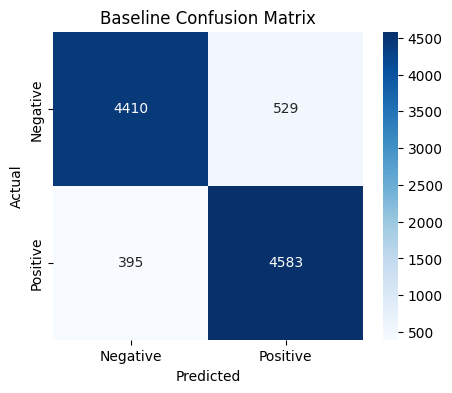

In [17]:
# Visualizing the accuracy of the model and the confusion matrix

y_pred = model.predict(X_test_v)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Baseline Confusion Matrix")
plt.show()

In [24]:
## Predicting sentiments of some review

def predict_review(text: str):
    cleaned = clean(text)
    vec = vectorizer.transform([cleaned])
    pred = model.predict(vec)[0]
    prob = model.predict_proba(vec)[0][pred]
    label = "Positive" if pred == 1 else "Negative"
    print(f"[{label} | {prob:.2%}] -> {text}")

samples = [
    "An absolute masterpiece. The pacing and cinematography were unforgettable.",
    "I wanted to like it, but the plot was a complete mess and the acting felt flat.",
    "Not bad at all, actually much better than I expected.",
    "Not good"
]

for s in samples:
    predict_review(s)

[Positive | 70.30%] -> An absolute masterpiece. The pacing and cinematography were unforgettable.
[Negative | 96.94%] -> I wanted to like it, but the plot was a complete mess and the acting felt flat.
[Negative | 85.22%] -> Not bad at all, actually much better than I expected.
[Negative | 85.68%] -> Not good


In [25]:
feature_names = vectorizer.get_feature_names_out()
weights = model.coef_[0]
vocab = dict(zip(feature_names, weights))

for phrase in ["not", "bad", "not bad", "good", "not good", "better", "expected"]:
    print(f"{phrase:<10} -> {vocab.get(phrase, 'NOT IN VOCAB')}")

not        -> -1.7999123258641172
bad        -> -8.674301969211209
not bad    -> 1.1337543338396319
good       -> 2.0251551873311704
not good   -> -2.2567639259843593
better     -> -1.970680194461501
expected   -> 0.07546189788793699


In [29]:
## Exporting the model and vectorizer and saving it in disk

joblib.dump(vectorizer, "backend/models/tfidf_vectorizer.joblib")
joblib.dump(model, "backend/models/sentiment_model.joblib")
print("Exported successfully!")

Exported successfully!
